**Predicción del Riesgo Ambiental por PM2.5 en Monterrey: Análisis Comparativo entre Análisis Discriminante Lineal y Árboles de Decisión**
---
***
El presente proyecto tiene como objetivo desarrollar y comparar modelos de clasificación, específicamente mediante Análisis Discriminante Lineal (LDA) y Árboles de Decisión, para predecir la calidad del aire y su riesgo para la salud pública. Para lograr esto, se utilizará una base de datos climática e industrial, transformando la concentración cuantitativa original de material particulado en un diagnóstico categórico de riesgo. Como criterio de separación, se establecerá un umbral físico de 25 µg/m³; cualquier registro que supere esta cifra se clasificará como un nivel que afecta a las personas (peligroso), mientras que los niveles inferiores se considerarán saludables. A través de este enfoque, se busca descubrir qué modelo resulta más adecuado y preciso para advertir sobre la toxicidad del aire.
Variables a analizar

* **PM2.5 (Material Particulado Fino) [Objetivo]**: Es la variable de salida (Target) que mide el nivel de contaminación tóxica en el aire. Para este modelo de clasificación, será convertida en una variable cualitativa binaria que indicará si el aire es "Dañino" (1) o "Saludable" (0) utilizando el límite de 25 µg/m³.

* **tavg (Temperatura promedio)**: Representa el calor en la ciudad. Actúa como un factor protector, ya que el aire caliente rompe el estancamiento y ayuda a dispersar la contaminación.

* **prcp (Precipitación)**: Cantidad de lluvia. Funciona como un limpiador natural de la atmósfera, "lavando" las partículas suspendidas.

* **wspd (Velocidad del viento)**: La fuerza de las corrientes de aire. Es fundamental para empujar y dispersar la nube de contaminación fuera de la ciudad.

* **pres (Presión atmosférica)**: Es un factor protector clave. Los sistemas de alta presión generan dinámicas que evitan que el smog se quede atrapado a nivel del suelo.

* **Automoviles**: Volumen de tráfico de vehículos particulares. Es una fuente constante de emisiones de combustión en la zona metropolitana.

* **Camiones_Pasajeros**: Flujo del transporte público. Su aumento es un indicador proxy de que hay menos autos particulares emitiendo gases simultáneamente en las calles.

* **Camiones_Carga**: Tráfico de vehículos logísticos pesados. Por sus motores a diésel, es el principal propulsor directo de las partículas tóxicas.

* **Actividad_Industrial**: Nivel de operación de las fábricas. Es una fuente masiva que inyecta contaminantes directamente a la atmósfera.

* **Es_Fin_De_Semana**: Variable dicotómica (dummy) creada para verificar si el hecho de que sea sábado o domingo afecta los niveles de material particulado al disminuir la actividad laboral y vehicular.

In [27]:
#Todas las librerias
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import mean_squared_error

df = pd.read_csv("Tabla_Analisis_Climatico.csv")
umbral_peligro = 25
df['Riesgo_PM25'] = (df['PM2.5'] > umbral_peligro).astype(int)

# Se eliminan 'Fecha' y 'PM2.5' (para evitar fuga de datos)
X = df.drop(columns=['Fecha', 'PM2.5', 'Riesgo_PM25'])
y = df['Riesgo_PM25']

# El parámetro 'stratify=y' garantiza que se conserve el balance de clases en ambos sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)

print("--- Balance de Clases Original (%) ---")
print(y.value_counts(normalize=True) * 100)

print("\n--- Balance de Clases en Entrenamiento (%) ---")
print(y_train.value_counts(normalize=True) * 100)

print("\n--- Balance de Clases en Prueba (%) ---")
print(y_test.value_counts(normalize=True) * 100)

--- Balance de Clases Original (%) ---
Riesgo_PM25
0    73.69863
1    26.30137
Name: proportion, dtype: float64

--- Balance de Clases en Entrenamiento (%) ---
Riesgo_PM25
0    73.630137
1    26.369863
Name: proportion, dtype: float64

--- Balance de Clases en Prueba (%) ---
Riesgo_PM25
0    73.972603
1    26.027397
Name: proportion, dtype: float64


**Definición del Problema y Partición de los Datos**
---
***
El problema central consiste en clasificar el riesgo en la calidad del aire mediante la variable binaria Riesgo_PM25, donde la clase 0 (Sin riesgo) agrupa los niveles de PM2.5 menores o iguales a 25, y la clase 1 (Con riesgo) los niveles superiores. Al analizar la distribución inicial, se identificó un claro desbalance: la clase 0 representa el 73.7% de los datos y la clase 1 el 26.3%.Los datos se dividieron en 80% para entrenamiento y 20% para prueba mediante un muestreo estratificado (stratify=y), garantizando que la proporción de clases se mantuviera prácticamente idéntica en ambos subconjuntos. Conservar este balance es fundamental, ya que el desbalance es una limitación importante al evaluar modelos; de no controlarlo, el algoritmo podría predecir siempre la clase mayoritaria y obtener una exactitud (accuracy) engañosamente alta, perdiendo la capacidad de identificar los verdaderos casos de riesgo.   Respecto a las características utilizadas, el conjunto de datos se mantuvo íntegro para la partición y para el modelo de árboles de decisión, el cual es capaz de manejar variables cualitativas sin necesidad de transformaciones adicionales. Sin embargo, la variable dummy fin_de_semana tuvo que ser excluida específicamente para el entrenamiento del modelo LDA. Esta decisión se justifica en los supuestos del modelo, ya que el Análisis Discriminante Lineal asume que los predictores siguen una distribución multivariada normal, un requisito probabilístico que una variable categórica no puede cumplir.

In [28]:
variables_lda = ["tavg", "prcp", "wspd", "pres", "Automoviles", "Camiones_Pasajeros", "Camiones_Carga"]
X_train_lda = X_train[variables_lda]
X_test_lda = X_test[variables_lda]

lda = LinearDiscriminantAnalysis()
lda.fit(X_train_lda, y_train)

coeficientes = lda.coef_[0]
interseccion = lda.intercept_[0]

ecuacion = f"{interseccion:.4f} "
for i, col in enumerate(variables_lda):
    ecuacion += f"+ ({coeficientes[i]:.4f} * {col}) "

mse_lda = mean_squared_error(y_test, y_pred_lda)
print("--- Ecuación de la Frontera Lineal de LDA ---")
print(f"0 = {ecuacion}")
print(f"Error Cuadrático Medio (MSE) de LDA: {mse_lda:.4f}")
print("-" * 65)

y_pred_lda = lda.predict(X_test_lda)

--- Ecuación de la Frontera Lineal de LDA ---
0 = -1392.1235 + (-0.0421 * tavg) + (0.0198 * prcp) + (-0.0561 * wspd) + (-0.2219 * pres) + (0.0001 * Automoviles) + (-0.0015 * Camiones_Pasajeros) + (0.0000 * Camiones_Carga) 
Error Cuadrático Medio (MSE) de LDA: 0.1918
-----------------------------------------------------------------


El mejor valor de alpha (α) encontrado es: 0.009058219178082187


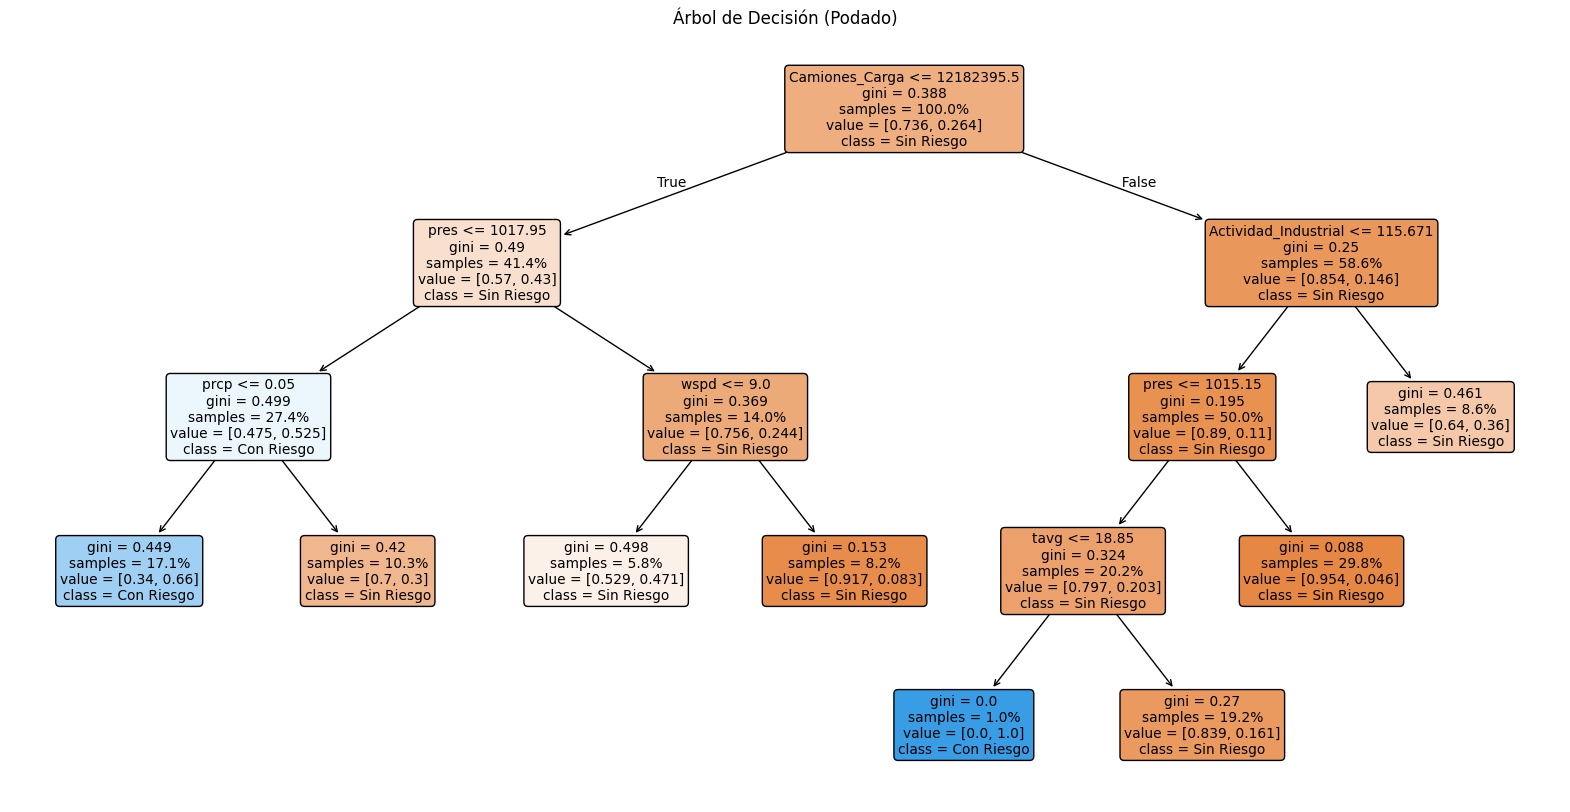

In [29]:
# Cost Complexity Pruning
clf = DecisionTreeClassifier(random_state=67)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=67, ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)

acc_scores = [accuracy_score(y_test, clf.predict(X_test)) for clf in clfs]
best_index = acc_scores.index(max(acc_scores))
best_alpha = ccp_alphas[best_index]
best_tree = clfs[best_index]

print(f"El mejor valor de alpha (α) encontrado es: {best_alpha}")

y_pred_tree = best_tree.predict(X_test)

plt.figure(figsize=(20, 10))
plot_tree(best_tree, filled=True, feature_names=X.columns, class_names=['Sin Riesgo', 'Con Riesgo'], rounded=True, proportion=True)
plt.title("Árbol de Decisión (Podado)")
plt.show()

--- Métricas para LDA ---
Exactitud (Accuracy):  0.8082
Sensibilidad (Recall): 0.6316
Especificidad:         0.8704
-----------------------------------
--- Métricas para Árbol de Decisión ---
Exactitud (Accuracy):  0.8356
Sensibilidad (Recall): 0.5789
Especificidad:         0.9259
-----------------------------------


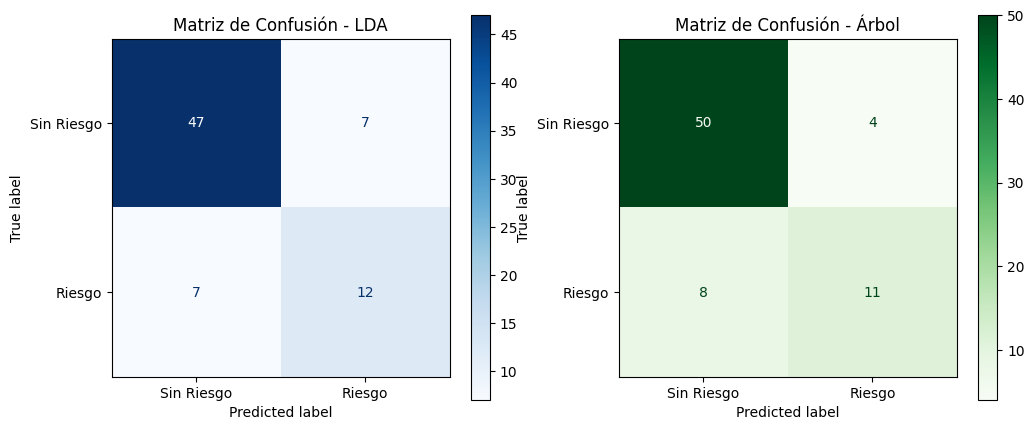

In [25]:
def calcular_metricas(y_true, y_pred, nombre_modelo):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    exactitud = (tp + tn) / (tp + fp + tn + fn)
    sensibilidad = tp / (tp + fn) # Proporción de casos positivos bien predichos
    especificidad = tn / (tn + fp) # Proporción de casos negativos bien predichos

    print(f"--- Métricas para {nombre_modelo} ---")
    print(f"Exactitud (Accuracy):  {exactitud:.4f}")
    print(f"Sensibilidad (Recall): {sensibilidad:.4f}")
    print(f"Especificidad:         {especificidad:.4f}")
    print("-" * 35)

calcular_metricas(y_test, y_pred_lda, "LDA")
calcular_metricas(y_test, y_pred_tree, "Árbol de Decisión")

# Matrices de confusión
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lda, ax=ax[0], cmap='Blues', display_labels=['Sin Riesgo', 'Riesgo'])
ax[0].set_title("Matriz de Confusión - LDA")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree, ax=ax[1], cmap='Greens', display_labels=['Sin Riesgo', 'Riesgo'])
ax[1].set_title("Matriz de Confusión - Árbol")
plt.show()

**Evaluación y comparación de los modelos**
---
***
Al analizar las métricas de desempeño, se observa una coherencia directa entre la estructura geométrica de cada algoritmo y sus resultados. El Árbol de Decisión obtuvo un mejor rendimiento global con una exactitud del 83.56% y una especificidad del 92.59%. Su naturaleza no lineal le permite segmentar el espacio mediante divisiones binarias recursivas, utilizando el Índice Gini como métrica para evaluar la impureza de los datos y minimizar el error en cada partición. Observando el modelo resultante, el nodo raíz (determinado por la variable Camiones_Carga) parte de una impureza inicial con un Gini de 0.388. Conforme el árbol se ramifica, el algoritmo evalúa variables sucesivas buscando aislar las clases, logrando en algunos nodos terminales (hojas) una pureza perfecta con un Gini de 0.0 para los casos con riesgo.

Para evitar que este árbol creciera demasiado y memorizara el ruido de los datos de entrenamiento (sobreajuste), se aplicó un proceso de poda iterativa conocido como cost complexity pruning. El mejor valor de $\alpha$ (alfa) encontrado fue de 0.009058. Este parámetro representa el nivel de penalización óptimo que generó la mejor versión del árbol: cortó las ramas innecesarias para mantener un modelo simple e interpretable, pero conservó las reglas suficientes para maximizar los aciertos en datos no vistos.

Por el contrario, el modelo de Análisis Discriminante Lineal (LDA) alcanzó una exactitud menor (80.82%). El error de estas predicciones se cuantificó globalmente mediante el Error Cuadrático Medio (MSE), obteniendo un valor de 0.1918. Esta métrica refleja de manera numérica la tasa de equivocaciones totales del clasificador. La mayor tasa de error radica en la rigidez de los supuestos del LDA: el modelo asume que los datos presentan una distribución multivariada normal y comparten una matriz de covarianza común entre clases, lo que lo obliga a trazar una frontera de decisión estrictamente lineal que no se adapta con tanta facilidad a la complejidad de los datos.

A pesar de su menor exactitud global, el LDA presenta una ventaja crítica para este problema específico: superó al árbol en sensibilidad (63.16% frente a 57.89%). La sensibilidad mide la proporción exacta de los verdaderos casos positivos de alto riesgo que el modelo logró predecir correctamente.

**CONCLUSION**
---
***
Considerando el contexto de alertar sobre niveles peligrosos de PM2.5, el modelo LDA se considera más adecuado si el propósito del sistema es la prevención y protección civil. Al igual que en los diagnósticos médicos, en problemas de riesgo ambiental la sensibilidad suele ser sumamente importante; es preferible tener falsas alarmas (falsos positivos) que fallar en identificar los días realmente peligrosos (falsos negativos), ya que esto último expondría a la población a la contaminación. No obstante, si el proyecto tiene un enfoque puramente analítico para que las autoridades comprendan qué variables detonan el riesgo, el Árbol de Decisión sería la mejor herramienta gracias a su capacidad de mostrar el peso de cada factor de forma visual y semejante a la toma de decisiones humana.

**REFERENCIAS**
--
***
1. INSTITUTO NACIONAL DE ECOLOGÍA y CAMBIO CLIMÁTICO. (s. f.). https://sinaica.inecc.gob.mx/
2. De Estadística Y, I. N. (s. f.). Parque vehicular. https://www.inegi.org.mx/temas/
vehiculos/#tabulados
3. El guardián del tiempo | Meteostat. (2025, 1 enero). https://meteostat.net/es/
place/mx/san-pedro-garza-garcia?s=76394&t=2025-01-01/2025-12-31
4. De Estadística Y, I. N. (s. f.-a). Indicador Mensual de la Actividad Industrial por
Entidad Federativa (IMAIEF). Año base 2018. https://www.inegi.org.mx/programas/
aief/2018/
5. Gemini (versión de 2026) [Modelo de lenguaje grande]. https://gemini.google.com

In [ ]:
!jupyter nbconvert --to html *.ipynb